Loaded: /oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/disj40_to_conj40_layer_token_components_w5_summary.csv
Rows: 1120
Components: ['attention' 'mlp']
Center layers: 28
Token offsets: 20
Examples per cell: 100 to 100

Baseline accuracies:
 source_accuracy  target_accuracy
             1.0             0.62

Effective window sizes:
 center_layer   patch_layers  effective_window_size
            0          0,1,2                      3
            1        0,1,2,3                      4
            2      0,1,2,3,4                      5
            3      1,2,3,4,5                      5
            4      2,3,4,5,6                      5
            5      3,4,5,6,7                      5
            6      4,5,6,7,8                      5
            7      5,6,7,8,9                      5
            8     6,7,8,9,10                      5
            9    7,8,9,10,11                      5
           10   8,9,10,11,12                      5
           11  9,10,11,12,13 

/users/aparasel/.conda/envs/patchscopes-llava/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 9248 (\N{SYMBOL FOR SPACE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


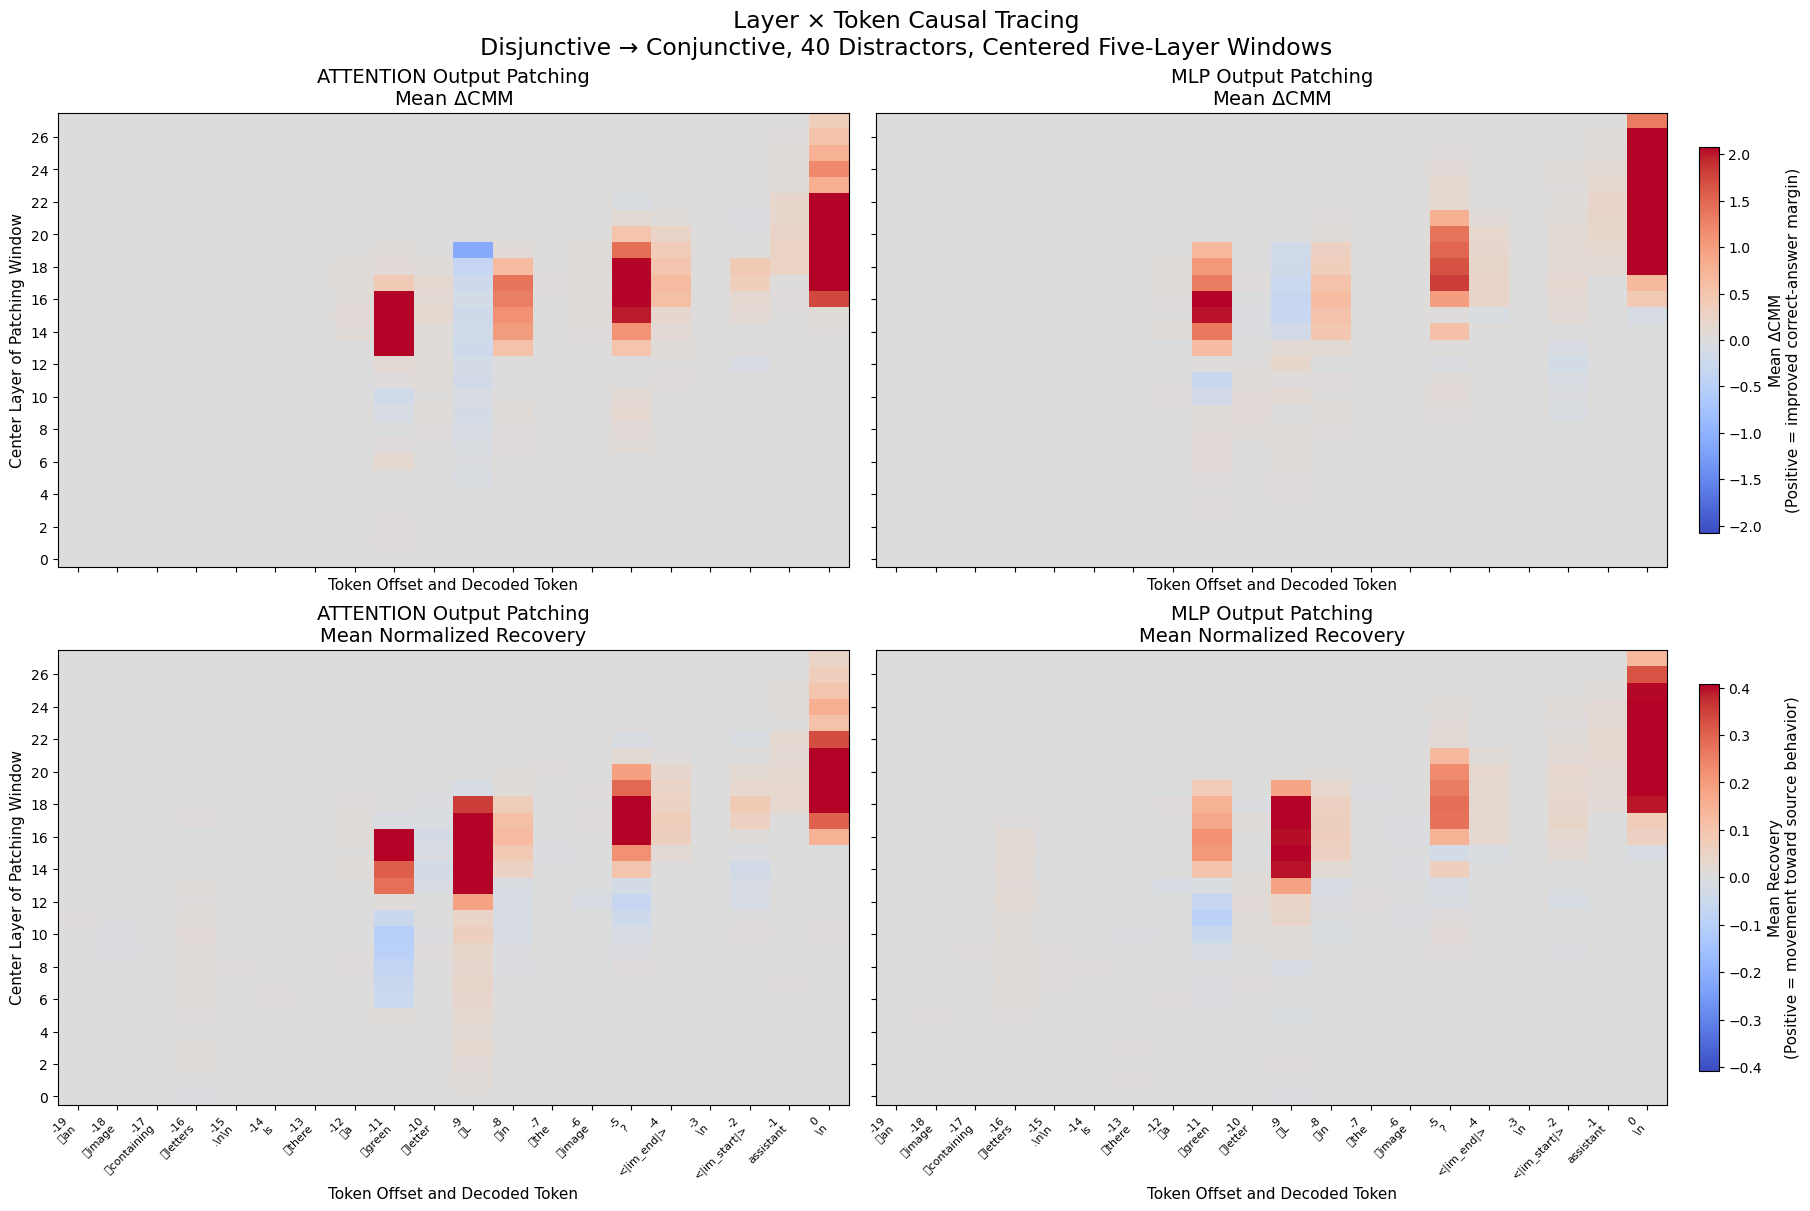

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================================
# PATHS
# ==========================================================

BASE = (
    "/oscar/data/epavlick/aparasel/"
    "Binding-Problem-Brown/Results"
)

RUN_NAME = (
    "disj40_to_conj40_"
    "layer_token_components_w5"
)

FINAL_SUMMARY_PATH = (
    f"{BASE}/{RUN_NAME}_summary.csv"
)

PARTIAL_SUMMARY_PATH = (
    f"{BASE}/{RUN_NAME}_summary_partial.csv"
)


# ==========================================================
# LOAD FINAL OR PARTIAL RESULTS
# ==========================================================

if os.path.exists(FINAL_SUMMARY_PATH):
    PATH = FINAL_SUMMARY_PATH

elif os.path.exists(PARTIAL_SUMMARY_PATH):
    PATH = PARTIAL_SUMMARY_PATH
    print("Final summary not found; using partial results.")

else:
    raise FileNotFoundError(
        "Could not find either:\n"
        f"{FINAL_SUMMARY_PATH}\n"
        f"{PARTIAL_SUMMARY_PATH}"
    )

df = pd.read_csv(PATH).copy()

print("Loaded:", PATH)
print("Rows:", len(df))
print("Components:", df["component"].unique())
print("Center layers:", df["center_layer"].nunique())
print("Token offsets:", df["token_offset"].nunique())
print("Examples per cell:", df["n"].min(), "to", df["n"].max())

df["mean_recovery"] = df["mean_recovery"].replace(
    [np.inf, -np.inf],
    np.nan,
)


# ==========================================================
# SANITY CHECKS
# ==========================================================

print("\nBaseline accuracies:")

print(
    df[
        [
            "source_accuracy",
            "target_accuracy",
        ]
    ]
    .drop_duplicates()
    .to_string(index=False)
)

print("\nEffective window sizes:")

print(
    df[
        [
            "center_layer",
            "patch_layers",
            "effective_window_size",
        ]
    ]
    .drop_duplicates()
    .sort_values("center_layer")
    .to_string(index=False)
)


# ==========================================================
# ORDERING
# ==========================================================

components = [
    component
    for component in ["attention", "mlp"]
    if component in df["component"].unique()
]

token_offsets = sorted(
    df["token_offset"].unique()
)

center_layers = sorted(
    df["center_layer"].unique()
)


# ==========================================================
# TOKEN LABELS
# ==========================================================

def clean_token_label(token):
    """
    Convert whitespace and special characters into labels
    that remain readable on the heatmap.
    """

    token = str(token)

    token = (
        token
        .replace("\n", "\\n")
        .replace("\t", "\\t")
        .replace("\r", "\\r")
        .replace(" ", "␠")
    )

    if len(token) > 14:
        token = token[:11] + "..."

    return token


token_lookup = (
    df[
        [
            "token_offset",
            "token",
        ]
    ]
    .drop_duplicates("token_offset")
    .set_index("token_offset")["token"]
    .to_dict()
)

token_labels = [
    (
        f"{offset}\n"
        f"{clean_token_label(token_lookup.get(offset, '?'))}"
    )
    for offset in token_offsets
]


# ==========================================================
# BUILD MATRICES
# ==========================================================

def make_matrix(
    data,
    component,
    metric,
):

    subset = data[
        data["component"] == component
    ].copy()

    matrix = subset.pivot(
        index="center_layer",
        columns="token_offset",
        values=metric,
    )

    matrix = matrix.reindex(
        index=center_layers,
        columns=token_offsets,
    )

    return matrix


matrices = {}

for component in components:

    matrices[(component, "mean_delta_cmm")] = (
        make_matrix(
            df,
            component,
            "mean_delta_cmm",
        )
    )

    matrices[(component, "mean_recovery")] = (
        make_matrix(
            df,
            component,
            "mean_recovery",
        )
    )


# ==========================================================
# SHARED COLOR SCALES
# ==========================================================

# Robust symmetric scale so a handful of extreme cells do
# not wash out the rest of the heatmap.

delta_values = np.concatenate([
    matrix.to_numpy().ravel()
    for (component, metric), matrix in matrices.items()
    if metric == "mean_delta_cmm"
])

delta_values = delta_values[
    np.isfinite(delta_values)
]

delta_vmax = np.nanpercentile(
    np.abs(delta_values),
    98,
)

if delta_vmax == 0:
    delta_vmax = 1.0


recovery_values = np.concatenate([
    matrix.to_numpy().ravel()
    for (component, metric), matrix in matrices.items()
    if metric == "mean_recovery"
])

recovery_values = recovery_values[
    np.isfinite(recovery_values)
]

recovery_vmax = np.nanpercentile(
    np.abs(recovery_values),
    98,
)

if recovery_vmax == 0:
    recovery_vmax = 1.0


# ==========================================================
# PLOT
# ==========================================================

fig, axes = plt.subplots(
    2,
    len(components),
    figsize=(18, 12),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)

# Ensure axes is always two-dimensional.
axes = np.asarray(axes)

if len(components) == 1:
    axes = axes.reshape(2, 1)


delta_images = []
recovery_images = []

for column_index, component in enumerate(components):

    # ------------------------------------------------------
    # DELTA CMM
    # ------------------------------------------------------

    delta_matrix = matrices[
        (component, "mean_delta_cmm")
    ]

    ax = axes[0, column_index]

    image = ax.imshow(
        delta_matrix.values,
        aspect="auto",
        origin="lower",
        interpolation="nearest",
        cmap="coolwarm",
        vmin=-delta_vmax,
        vmax=delta_vmax,
    )

    delta_images.append(image)

    ax.set_title(
        f"{component.upper()} Output Patching\n"
        r"Mean $\Delta$CMM",
        fontsize=14,
    )

    # ------------------------------------------------------
    # RECOVERY
    # ------------------------------------------------------

    recovery_matrix = matrices[
        (component, "mean_recovery")
    ]

    ax = axes[1, column_index]

    image = ax.imshow(
        recovery_matrix.values,
        aspect="auto",
        origin="lower",
        interpolation="nearest",
        cmap="coolwarm",
        vmin=-recovery_vmax,
        vmax=recovery_vmax,
    )

    recovery_images.append(image)

    ax.set_title(
        f"{component.upper()} Output Patching\n"
        "Mean Normalized Recovery",
        fontsize=14,
    )


# ==========================================================
# AXES
# ==========================================================

y_step = 2

for row_index in range(2):

    for column_index in range(len(components)):

        ax = axes[row_index, column_index]

        ax.set_yticks(
            np.arange(
                0,
                len(center_layers),
                y_step,
            )
        )

        ax.set_yticklabels(
            center_layers[::y_step]
        )

        ax.set_xticks(
            np.arange(
                len(token_offsets)
            )
        )

        ax.set_xticklabels(
            token_labels,
            rotation=45,
            ha="right",
            fontsize=8,
        )

        ax.set_xlabel(
            "Token Offset and Decoded Token",
            fontsize=11,
        )

        if column_index == 0:
            ax.set_ylabel(
                "Center Layer of Patching Window",
                fontsize=11,
            )


# ==========================================================
# COLORBARS
# ==========================================================

delta_colorbar = fig.colorbar(
    delta_images[0],
    ax=axes[0, :].tolist(),
    shrink=0.85,
    pad=0.02,
)

delta_colorbar.set_label(
    r"Mean $\Delta$CMM"
    "\n(Positive = improved correct-answer margin)",
    fontsize=11,
)


recovery_colorbar = fig.colorbar(
    recovery_images[0],
    ax=axes[1, :].tolist(),
    shrink=0.85,
    pad=0.02,
)

recovery_colorbar.set_label(
    "Mean Recovery"
    "\n(Positive = movement toward source behavior)",
    fontsize=11,
)


# ==========================================================
# TITLE
# ==========================================================

fig.suptitle(
    "Layer × Token Causal Tracing\n"
    "Disjunctive → Conjunctive, 40 Distractors, "
    "Centered Five-Layer Windows",
    fontsize=17,
)

plt.show()

Loaded: /oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/disj40_to_conj40_layer_token_components_w5.csv
Detailed rows: 112000
Columns: ['trial', 'target_present', 'source_path', 'target_path', 'component', 'center_layer', 'patch_layers', 'requested_window_size', 'effective_window_size', 'token_offset', 'token_position', 'token_id', 'token', 'source_prediction', 'source_correct', 'source_cmm', 'target_prediction', 'target_correct', 'target_cmm', 'patched_prediction', 'patched_correct', 'patched_cmm', 'delta_cmm', 'source_target_cmm_gap', 'recovery', 'mean_patch_l2_change']

Examples per cell:
                min  max  mean
target_present                
Target absent    50   50  50.0
Target present   50   50  50.0

Saved split summary: /oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/disj40_to_conj40_layer_token_components_w5_summary_by_target_presence.csv


/users/aparasel/.conda/envs/patchscopes-llava/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 9248 (\N{SYMBOL FOR SPACE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


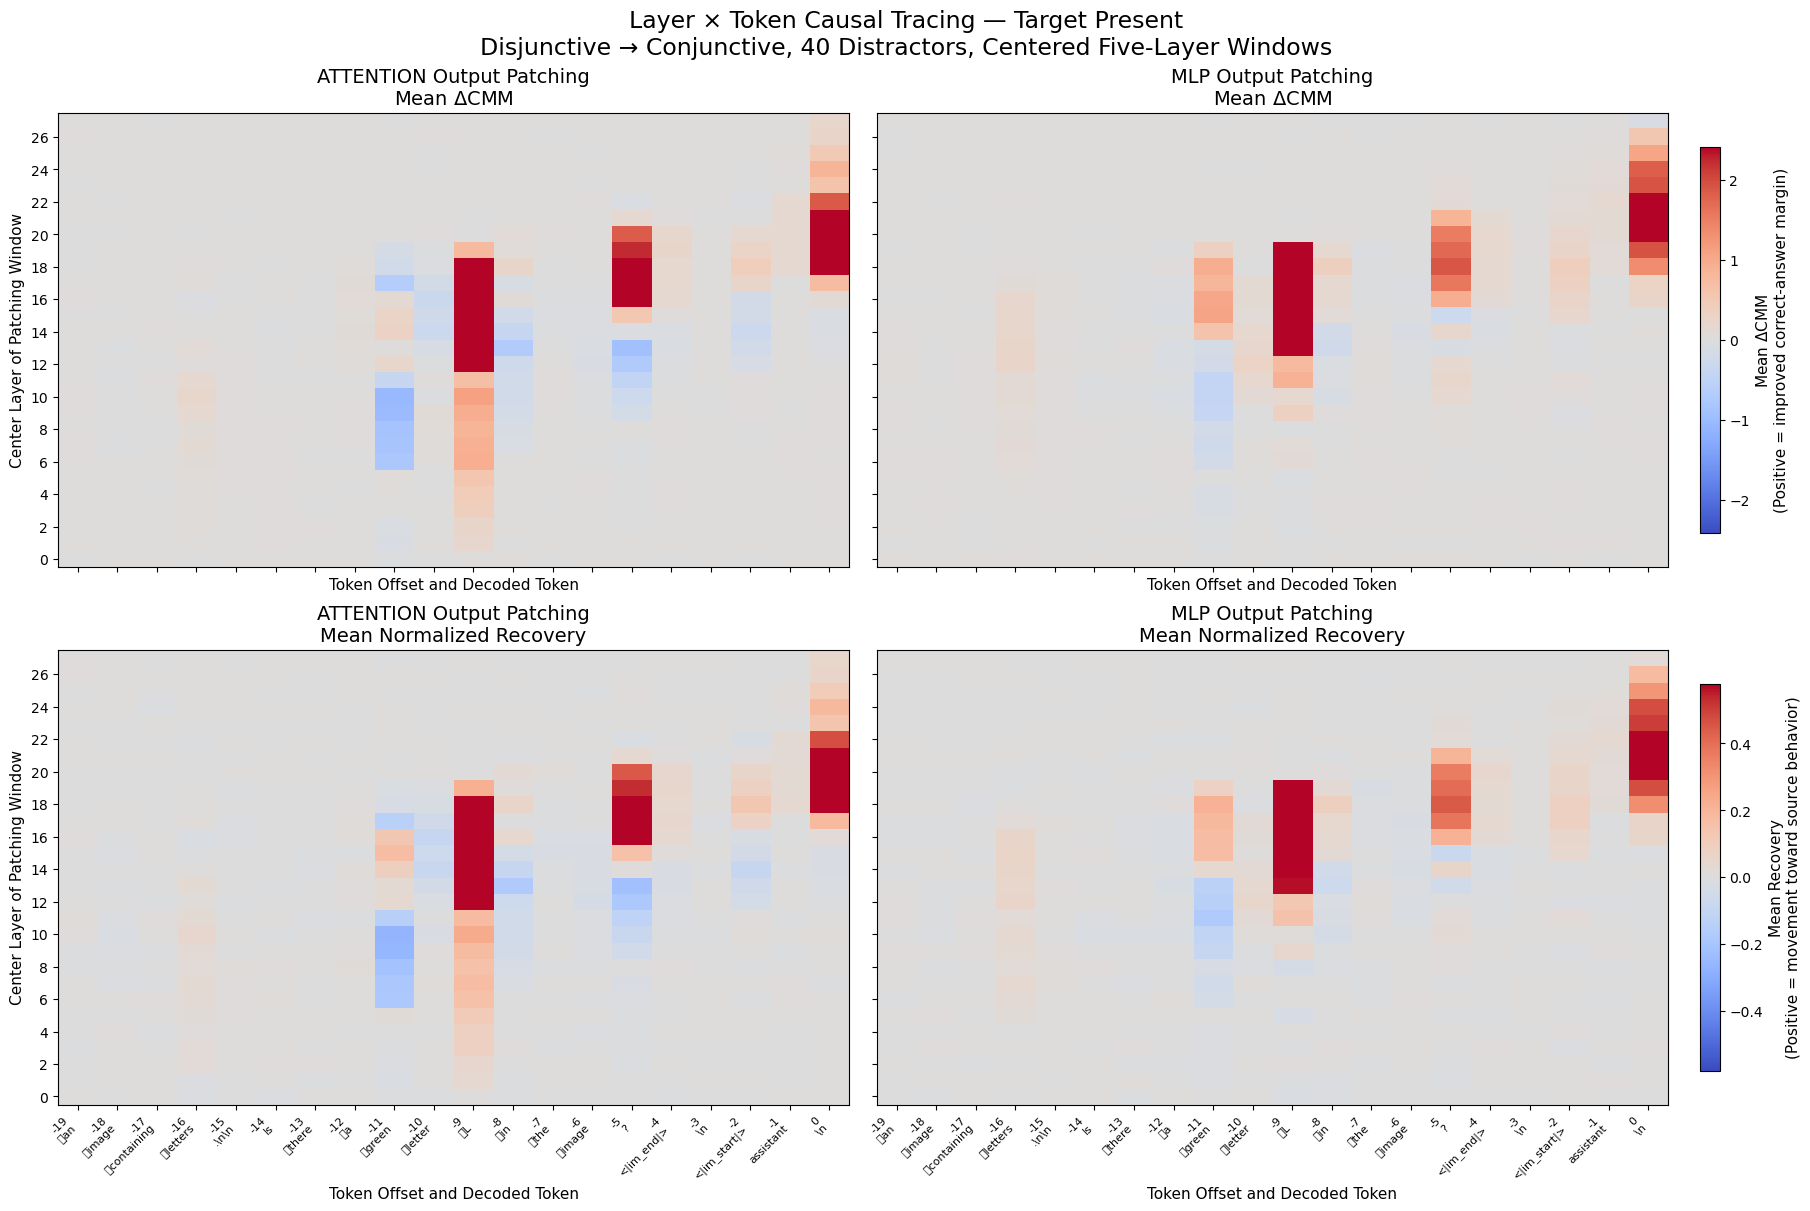

/users/aparasel/.conda/envs/patchscopes-llava/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 9248 (\N{SYMBOL FOR SPACE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


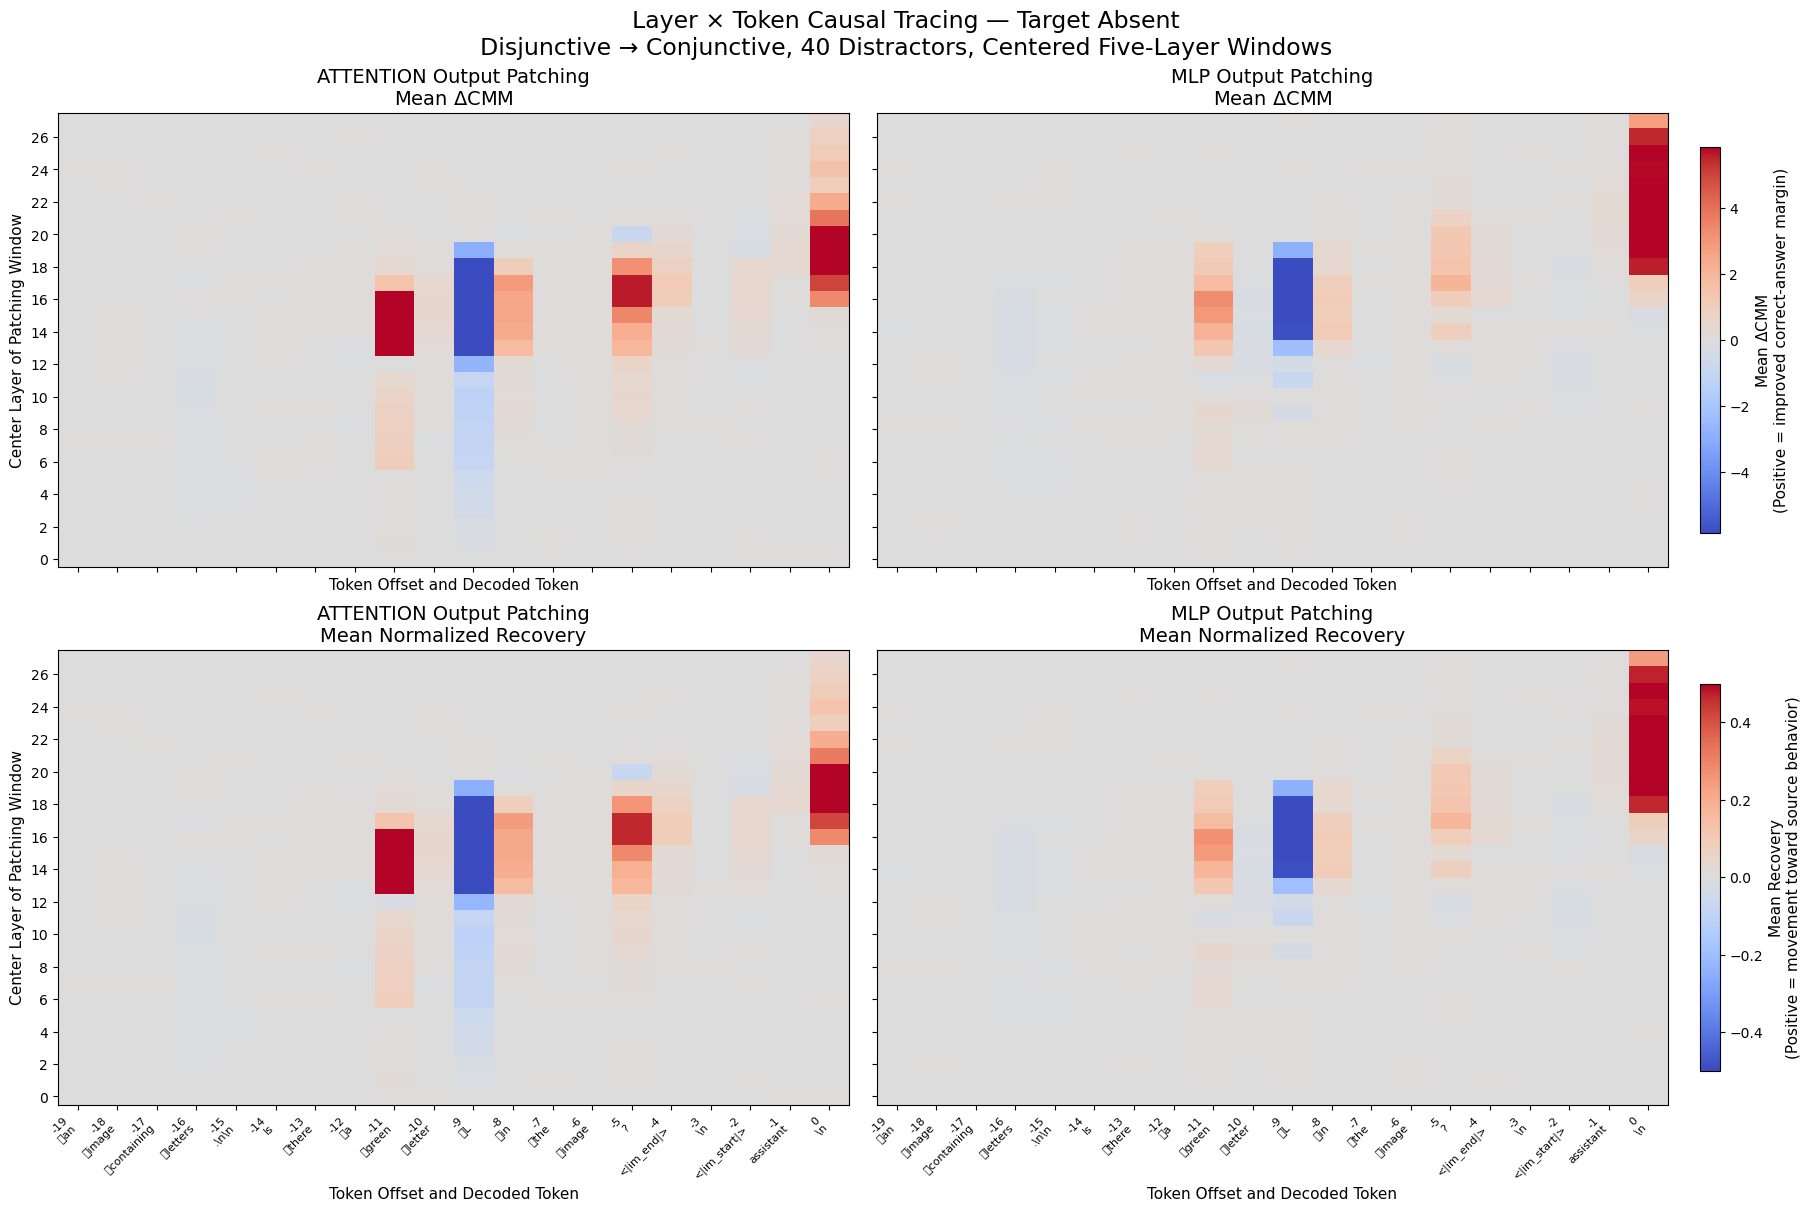

In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================================
# PATHS
# ==========================================================

BASE = (
    "/oscar/data/epavlick/aparasel/"
    "Binding-Problem-Brown/Results"
)

RUN_NAME = "disj40_to_conj40_layer_token_components_w5"

# Load detailed results, NOT the already-aggregated summary.
FINAL_DETAIL_PATH = f"{BASE}/{RUN_NAME}.csv"
PARTIAL_DETAIL_PATH = f"{BASE}/{RUN_NAME}_partial.csv"

if os.path.exists(FINAL_DETAIL_PATH):
    PATH = FINAL_DETAIL_PATH
elif os.path.exists(PARTIAL_DETAIL_PATH):
    PATH = PARTIAL_DETAIL_PATH
    print("Final detailed results not found; using partial results.")
else:
    raise FileNotFoundError(
        "Could not find either detailed-results file:\n"
        f"{FINAL_DETAIL_PATH}\n"
        f"{PARTIAL_DETAIL_PATH}"
    )

detail_df = pd.read_csv(PATH).copy()

print("Loaded:", PATH)
print("Detailed rows:", len(detail_df))
print("Columns:", detail_df.columns.tolist())

if "target_present" not in detail_df.columns:
    raise ValueError(
        "This file does not contain `target_present`. "
        "Make sure you loaded the detailed CSV rather than *_summary.csv."
    )

# Robust boolean parsing
detail_df["target_present"] = (
    detail_df["target_present"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map({
        "true": True,
        "false": False,
        "1": True,
        "0": False,
    })
)

if detail_df["target_present"].isna().any():
    raise ValueError(
        "Could not parse some `target_present` values:\n"
        f"{detail_df['target_present'].unique()}"
    )

detail_df["recovery"] = detail_df["recovery"].replace(
    [np.inf, -np.inf],
    np.nan,
)


# ==========================================================
# RECREATE SUMMARY, PRESERVING TARGET PRESENCE
# ==========================================================

GROUP_COLUMNS = [
    "component",
    "center_layer",
    "patch_layers",
    "requested_window_size",
    "effective_window_size",
    "token_offset",
    "token_position",
    "token_id",
    "token",
    "target_present",
]

df = (
    detail_df
    .groupby(
        GROUP_COLUMNS,
        as_index=False,
        dropna=False,
    )
    .agg(
        n=("trial", "size"),
        source_accuracy=("source_correct", "mean"),
        target_accuracy=("target_correct", "mean"),
        patched_accuracy=("patched_correct", "mean"),
        mean_source_cmm=("source_cmm", "mean"),
        mean_target_cmm=("target_cmm", "mean"),
        mean_patched_cmm=("patched_cmm", "mean"),
        mean_delta_cmm=("delta_cmm", "mean"),
        median_delta_cmm=("delta_cmm", "median"),
        mean_recovery=("recovery", "mean"),
        median_recovery=("recovery", "median"),
        mean_patch_l2_change=("mean_patch_l2_change", "mean"),
    )
    .sort_values([
        "target_present",
        "component",
        "token_offset",
        "center_layer",
    ])
    .reset_index(drop=True)
)

print("\nExamples per cell:")
print(
    df.groupby("target_present")["n"]
    .agg(["min", "max", "mean"])
    .rename(index={True: "Target present", False: "Target absent"})
)

# Optional: save the correctly split summary for future use.
SPLIT_SUMMARY_PATH = f"{BASE}/{RUN_NAME}_summary_by_target_presence.csv"
df.to_csv(SPLIT_SUMMARY_PATH, index=False)
print("\nSaved split summary:", SPLIT_SUMMARY_PATH)


# ==========================================================
# ORDERING AND TOKEN LABELS
# ==========================================================

components = [
    component
    for component in ["attention", "mlp"]
    if component in df["component"].unique()
]

token_offsets = sorted(df["token_offset"].unique())
center_layers = sorted(df["center_layer"].unique())


def clean_token_label(token):
    token = str(token)

    token = (
        token
        .replace("\n", "\\n")
        .replace("\t", "\\t")
        .replace("\r", "\\r")
        .replace(" ", "␠")
    )

    if len(token) > 14:
        token = token[:11] + "..."

    return token


token_lookup = (
    df[["token_offset", "token"]]
    .drop_duplicates("token_offset")
    .set_index("token_offset")["token"]
    .to_dict()
)

token_labels = [
    f"{offset}\n{clean_token_label(token_lookup.get(offset, '?'))}"
    for offset in token_offsets
]


# ==========================================================
# PLOTTING HELPERS
# ==========================================================

def make_matrix(data, component, metric):
    matrix = (
        data[data["component"] == component]
        .pivot(
            index="center_layer",
            columns="token_offset",
            values=metric,
        )
        .reindex(
            index=center_layers,
            columns=token_offsets,
        )
    )

    return matrix


def safe_symmetric_vmax(values):
    values = values[np.isfinite(values)]

    if len(values) == 0:
        return 1.0

    vmax = np.nanpercentile(np.abs(values), 98)

    return 1.0 if vmax == 0 else vmax


def plot_condition(condition_df, condition_label):
    matrices = {}

    for component in components:
        matrices[(component, "mean_delta_cmm")] = make_matrix(
            condition_df,
            component,
            "mean_delta_cmm",
        )

        matrices[(component, "mean_recovery")] = make_matrix(
            condition_df,
            component,
            "mean_recovery",
        )

    # Color scale is shared across the attention and MLP panels
    # within this target-presence condition.
    delta_values = np.concatenate([
        matrix.to_numpy().ravel()
        for (component, metric), matrix in matrices.items()
        if metric == "mean_delta_cmm"
    ])

    recovery_values = np.concatenate([
        matrix.to_numpy().ravel()
        for (component, metric), matrix in matrices.items()
        if metric == "mean_recovery"
    ])

    delta_vmax = safe_symmetric_vmax(delta_values)
    recovery_vmax = safe_symmetric_vmax(recovery_values)

    fig, axes = plt.subplots(
        2,
        len(components),
        figsize=(18, 12),
        sharex=True,
        sharey=True,
        constrained_layout=True,
    )

    axes = np.asarray(axes)
    if len(components) == 1:
        axes = axes.reshape(2, 1)

    delta_images = []
    recovery_images = []

    for column_index, component in enumerate(components):

        # --------------------------------------------------
        # Mean delta CMM
        # --------------------------------------------------

        delta_matrix = matrices[(component, "mean_delta_cmm")]
        ax = axes[0, column_index]

        image = ax.imshow(
            delta_matrix.values,
            aspect="auto",
            origin="lower",
            interpolation="nearest",
            cmap="coolwarm",
            vmin=-delta_vmax,
            vmax=delta_vmax,
        )

        delta_images.append(image)

        ax.set_title(
            f"{component.upper()} Output Patching\n"
            r"Mean $\Delta$CMM",
            fontsize=14,
        )

        # --------------------------------------------------
        # Mean normalized recovery
        # --------------------------------------------------

        recovery_matrix = matrices[(component, "mean_recovery")]
        ax = axes[1, column_index]

        image = ax.imshow(
            recovery_matrix.values,
            aspect="auto",
            origin="lower",
            interpolation="nearest",
            cmap="coolwarm",
            vmin=-recovery_vmax,
            vmax=recovery_vmax,
        )

        recovery_images.append(image)

        ax.set_title(
            f"{component.upper()} Output Patching\n"
            "Mean Normalized Recovery",
            fontsize=14,
        )

    # ------------------------------------------------------
    # Axis labels
    # ------------------------------------------------------

    y_step = 2

    for row_index in range(2):
        for column_index in range(len(components)):
            ax = axes[row_index, column_index]

            ax.set_yticks(
                np.arange(0, len(center_layers), y_step)
            )
            ax.set_yticklabels(center_layers[::y_step])

            ax.set_xticks(np.arange(len(token_offsets)))
            ax.set_xticklabels(
                token_labels,
                rotation=45,
                ha="right",
                fontsize=8,
            )

            ax.set_xlabel(
                "Token Offset and Decoded Token",
                fontsize=11,
            )

            if column_index == 0:
                ax.set_ylabel(
                    "Center Layer of Patching Window",
                    fontsize=11,
                )

    # ------------------------------------------------------
    # Colorbars
    # ------------------------------------------------------

    delta_colorbar = fig.colorbar(
        delta_images[0],
        ax=axes[0, :].tolist(),
        shrink=0.85,
        pad=0.02,
    )

    delta_colorbar.set_label(
        r"Mean $\Delta$CMM"
        "\n(Positive = improved correct-answer margin)",
        fontsize=11,
    )

    recovery_colorbar = fig.colorbar(
        recovery_images[0],
        ax=axes[1, :].tolist(),
        shrink=0.85,
        pad=0.02,
    )

    recovery_colorbar.set_label(
        "Mean Recovery"
        "\n(Positive = movement toward source behavior)",
        fontsize=11,
    )

    fig.suptitle(
        f"Layer × Token Causal Tracing — Target {condition_label}\n"
        "Disjunctive → Conjunctive, 40 Distractors, "
        "Centered Five-Layer Windows",
        fontsize=17,
    )

    plt.show()


# ==========================================================
# TARGET-PRESENT FIGURE
# ==========================================================

plot_condition(
    df[df["target_present"]].copy(),
    condition_label="Present",
)


# ==========================================================
# TARGET-ABSENT FIGURE
# ==========================================================

plot_condition(
    df[~df["target_present"]].copy(),
    condition_label="Absent",
)

In [4]:
df

,component,center_layer,patch_layers,requested_window_size,effective_window_size,token_offset,token_position,token_id,token,n,...,target_accuracy,patched_accuracy,mean_source_cmm,mean_target_cmm,mean_patched_cmm,mean_delta_cmm,median_delta_cmm,mean_recovery,median_recovery,mean_patch_l2_change
0,attention,0,"0,1,2",5,3,-19,299,458,an,100,...,0.62,0.61,8.415,0.28875,0.27500,-0.01375,0.0000,0.000761,0.000000,0.358531
1,attention,1,"0,1,2,3",5,4,-19,299,458,an,100,...,0.62,0.61,8.415,0.28875,0.28500,-0.00375,0.0000,-0.001608,0.000000,0.483141
2,attention,2,"0,1,2,3,4",5,5,-19,299,458,an,100,...,0.62,0.61,8.415,0.28875,0.27875,-0.01000,0.0000,-0.001020,0.000000,0.539370
3,attention,3,"1,2,3,4,5",5,5,-19,299,458,an,100,...,0.62,0.61,8.415,0.28875,0.28125,-0.00750,0.0000,-0.004522,0.000000,0.617135
4,attention,4,"2,3,4,5,6",5,5,-19,299,458,an,100,...,0.62,0.63,8.415,0.28875,0.29000,0.00125,0.0000,-0.000602,0.000000,0.878471
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1115,mlp,23,"21,22,23,24,25",5,5,0,318,198,\n,100,...,0.62,0.95,8.415,0.28875,4.25375,3.96500,4.1875,0.504527,0.494680,38.491128
1116,mlp,24,"22,23,24,25,26",5,5,0,318,198,\n,100,...,0.62,0.95,8.415,0.28875,4.09750,3.80875,4.2500,0.478558,0.473401,43.771597
1117,mlp,25,"23,24,25,26,27",5,5,0,318,198,\n,100,...,0.62,0.88,8.415,0.28875,3.81375,3.52500,3.5000,0.402805,0.406250,86.230874
1118,mlp,26,"24,25,26,27",5,4,0,318,198,\n,100,...,0.62,0.86,8.415,0.28875,3.30375,3.01500,2.8750,0.324158,0.341079,106.679469


Loaded: /oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/disj40_to_conj40_layer_token_components_w5_summary.csv
Rows: 1120
Components: ['attention' 'mlp']
Center layers: 28
Token offsets: 20
Examples per cell: 100 to 100

Baseline accuracies:
 source_accuracy  target_accuracy
             1.0             0.62

Effective window sizes:
 center_layer   patch_layers  effective_window_size
            0          0,1,2                      3
            1        0,1,2,3                      4
            2      0,1,2,3,4                      5
            3      1,2,3,4,5                      5
            4      2,3,4,5,6                      5
            5      3,4,5,6,7                      5
            6      4,5,6,7,8                      5
            7      5,6,7,8,9                      5
            8     6,7,8,9,10                      5
            9    7,8,9,10,11                      5
           10   8,9,10,11,12                      5
           11  9,10,11,12,13 

/tmp/ipykernel_2550612/327816479.py:398: UserWarning: Glyph 9248 (\N{SYMBOL FOR SPACE}) missing from font(s) DejaVu Sans.
  fig.savefig(


Saved: /oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/disj40_to_conj40_layer_token_components_w5_mean_recovery.pdf


/users/aparasel/.conda/envs/patchscopes-llava/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 9248 (\N{SYMBOL FOR SPACE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


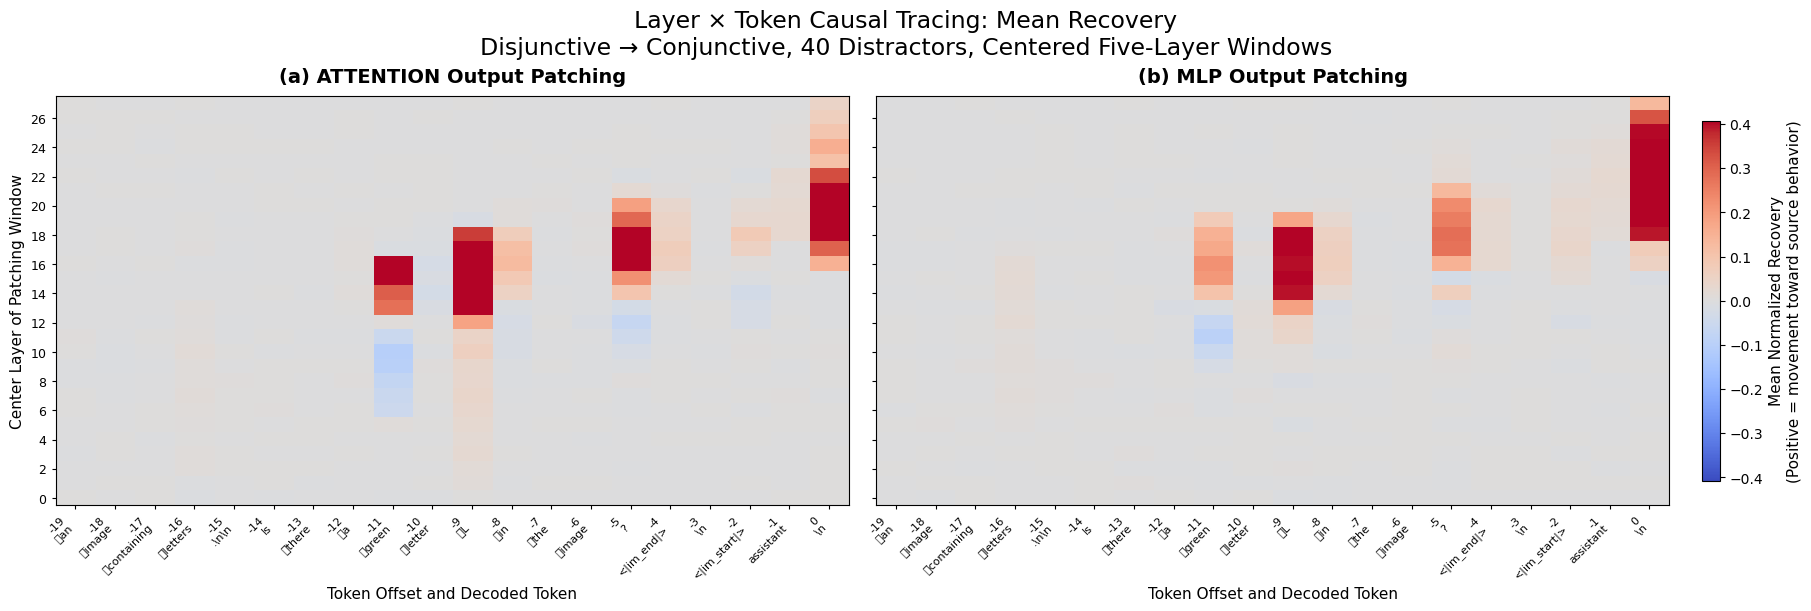

In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================================
# PATHS
# ==========================================================

BASE = (
    "/oscar/data/epavlick/aparasel/"
    "Binding-Problem-Brown/Results"
)

RUN_NAME = (
    "disj40_to_conj40_"
    "layer_token_components_w5"
)

FINAL_SUMMARY_PATH = (
    f"{BASE}/{RUN_NAME}_summary.csv"
)

PARTIAL_SUMMARY_PATH = (
    f"{BASE}/{RUN_NAME}_summary_partial.csv"
)


# ==========================================================
# LOAD FINAL OR PARTIAL RESULTS
# ==========================================================

if os.path.exists(FINAL_SUMMARY_PATH):
    PATH = FINAL_SUMMARY_PATH

elif os.path.exists(PARTIAL_SUMMARY_PATH):
    PATH = PARTIAL_SUMMARY_PATH
    print("Final summary not found; using partial results.")

else:
    raise FileNotFoundError(
        "Could not find either:\n"
        f"{FINAL_SUMMARY_PATH}\n"
        f"{PARTIAL_SUMMARY_PATH}"
    )

df = pd.read_csv(PATH).copy()

print("Loaded:", PATH)
print("Rows:", len(df))
print("Components:", df["component"].unique())
print("Center layers:", df["center_layer"].nunique())
print("Token offsets:", df["token_offset"].nunique())
print("Examples per cell:", df["n"].min(), "to", df["n"].max())

df["mean_recovery"] = df["mean_recovery"].replace(
    [np.inf, -np.inf],
    np.nan,
)


# ==========================================================
# SANITY CHECKS
# ==========================================================

print("\nBaseline accuracies:")

print(
    df[
        [
            "source_accuracy",
            "target_accuracy",
        ]
    ]
    .drop_duplicates()
    .to_string(index=False)
)

print("\nEffective window sizes:")

print(
    df[
        [
            "center_layer",
            "patch_layers",
            "effective_window_size",
        ]
    ]
    .drop_duplicates()
    .sort_values("center_layer")
    .to_string(index=False)
)


# ==========================================================
# ORDERING
# ==========================================================

components = [
    component
    for component in ["attention", "mlp"]
    if component in df["component"].unique()
]

token_offsets = sorted(
    df["token_offset"].unique()
)

center_layers = sorted(
    df["center_layer"].unique()
)


# ==========================================================
# TOKEN LABELS
# ==========================================================

def clean_token_label(token):
    """
    Convert whitespace and special characters into labels
    that remain readable on the heatmap.
    """

    token = str(token)

    token = (
        token
        .replace("\n", "\\n")
        .replace("\t", "\\t")
        .replace("\r", "\\r")
        .replace(" ", "␠")
    )

    if len(token) > 14:
        token = token[:11] + "..."

    return token


token_lookup = (
    df[
        [
            "token_offset",
            "token",
        ]
    ]
    .drop_duplicates("token_offset")
    .set_index("token_offset")["token"]
    .to_dict()
)

token_labels = [
    (
        f"{offset}\n"
        f"{clean_token_label(token_lookup.get(offset, '?'))}"
    )
    for offset in token_offsets
]


# ==========================================================
# BUILD MATRICES
# ==========================================================

def make_matrix(
    data,
    component,
    metric,
):

    subset = data[
        data["component"] == component
    ].copy()

    matrix = subset.pivot(
        index="center_layer",
        columns="token_offset",
        values=metric,
    )

    matrix = matrix.reindex(
        index=center_layers,
        columns=token_offsets,
    )

    return matrix


matrices = {}

for component in components:

    matrices[(component, "mean_delta_cmm")] = (
        make_matrix(
            df,
            component,
            "mean_delta_cmm",
        )
    )

    matrices[(component, "mean_recovery")] = (
        make_matrix(
            df,
            component,
            "mean_recovery",
        )
    )


# ==========================================================
# SHARED COLOR SCALES
# ==========================================================

# Robust symmetric scale so a handful of extreme cells do
# not wash out the rest of the heatmap.

delta_values = np.concatenate([
    matrix.to_numpy().ravel()
    for (component, metric), matrix in matrices.items()
    if metric == "mean_delta_cmm"
])

delta_values = delta_values[
    np.isfinite(delta_values)
]

delta_vmax = np.nanpercentile(
    np.abs(delta_values),
    98,
)

if delta_vmax == 0:
    delta_vmax = 1.0


recovery_values = np.concatenate([
    matrix.to_numpy().ravel()
    for (component, metric), matrix in matrices.items()
    if metric == "mean_recovery"
])

recovery_values = recovery_values[
    np.isfinite(recovery_values)
]

recovery_vmax = np.nanpercentile(
    np.abs(recovery_values),
    98,
)

if recovery_vmax == 0:
    recovery_vmax = 1.0


# ==========================================================
# PLOT
# ==========================================================
# ==========================================================
# PLOT: MEAN RECOVERY ONLY
# ==========================================================

# Restore Matplotlib's clean default style.
# DejaVu Sans also supports the visible-space symbol "␠".
plt.rcParams.update(plt.rcParamsDefault)

fig, axes = plt.subplots(
    1,
    len(components),
    figsize=(18, 6),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)

axes = np.atleast_1d(axes)

recovery_images = []
panel_labels = ["(a)", "(b)", "(c)"]

for column_index, component in enumerate(components):

    recovery_matrix = matrices[
        (component, "mean_recovery")
    ]

    ax = axes[column_index]

    image = ax.imshow(
        recovery_matrix.values,
        aspect="auto",
        origin="lower",
        interpolation="nearest",
        cmap="coolwarm",
        vmin=-recovery_vmax,
        vmax=recovery_vmax,
    )

    recovery_images.append(image)

    ax.set_title(
        f"{panel_labels[column_index]} "
        f"{component.upper()} Output Patching",
        fontsize=14,
        fontweight="semibold",
        pad=10,
    )


# ==========================================================
# AXES
# ==========================================================

y_step = 2

for column_index, ax in enumerate(axes):

    # Center layers
    ax.set_yticks(
        np.arange(
            0,
            len(center_layers),
            y_step,
        )
    )

    ax.set_yticklabels(
        center_layers[::y_step],
        fontsize=9,
    )

    # Token offsets and decoded tokens
    ax.set_xticks(
        np.arange(len(token_offsets))
    )

    ax.set_xticklabels(
        token_labels,
        rotation=45,
        ha="right",
        fontsize=8,
    )

    ax.set_xlabel(
        "Token Offset and Decoded Token",
        fontsize=11,
    )

    if column_index == 0:
        ax.set_ylabel(
            "Center Layer of Patching Window",
            fontsize=11,
        )

    ax.tick_params(
        axis="both",
        length=3,
    )


# ==========================================================
# SHARED COLORBAR
# ==========================================================

recovery_colorbar = fig.colorbar(
    recovery_images[0],
    ax=axes.tolist(),
    shrink=0.88,
    pad=0.02,
)

recovery_colorbar.set_label(
    "Mean Normalized Recovery\n"
    "(Positive = movement toward source behavior)",
    fontsize=11,
)


# ==========================================================
# TITLE
# ==========================================================

fig.suptitle(
    "Layer × Token Causal Tracing: Mean Recovery\n"
    "Disjunctive → Conjunctive, 40 Distractors, "
    "Centered Five-Layer Windows",
    fontsize=17,
)


# ==========================================================
# SAVE
# ==========================================================

OUTPUT_PDF = (
    f"{BASE}/{RUN_NAME}_mean_recovery.pdf"
)

fig.savefig(
    OUTPUT_PDF,
    format="pdf",
    bbox_inches="tight",
)

print("Saved:", OUTPUT_PDF)

plt.show()

# Green T Disjunctive source causal tracing

Loaded: /oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/disj35_T_to_conj35_layer_token_components_w5.csv
Detailed rows: 112000
Columns: ['trial', 'target_present', 'source_path', 'target_path', 'component', 'center_layer', 'patch_layers', 'requested_window_size', 'effective_window_size', 'token_offset', 'token_position', 'token_id', 'token', 'source_prediction', 'source_correct', 'source_cmm', 'target_prediction', 'target_correct', 'target_cmm', 'patched_prediction', 'patched_correct', 'patched_cmm', 'delta_cmm', 'source_target_cmm_gap', 'recovery', 'mean_patch_l2_change']

Examples per cell:
                min  max  mean
target_present                
Target absent    50   50  50.0
Target present   50   50  50.0

Saved split summary: /oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/disj35_T_to_conj35_layer_token_components_w5_summary_by_target_presence.csv


/users/aparasel/.conda/envs/patchscopes-llava/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 9248 (\N{SYMBOL FOR SPACE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


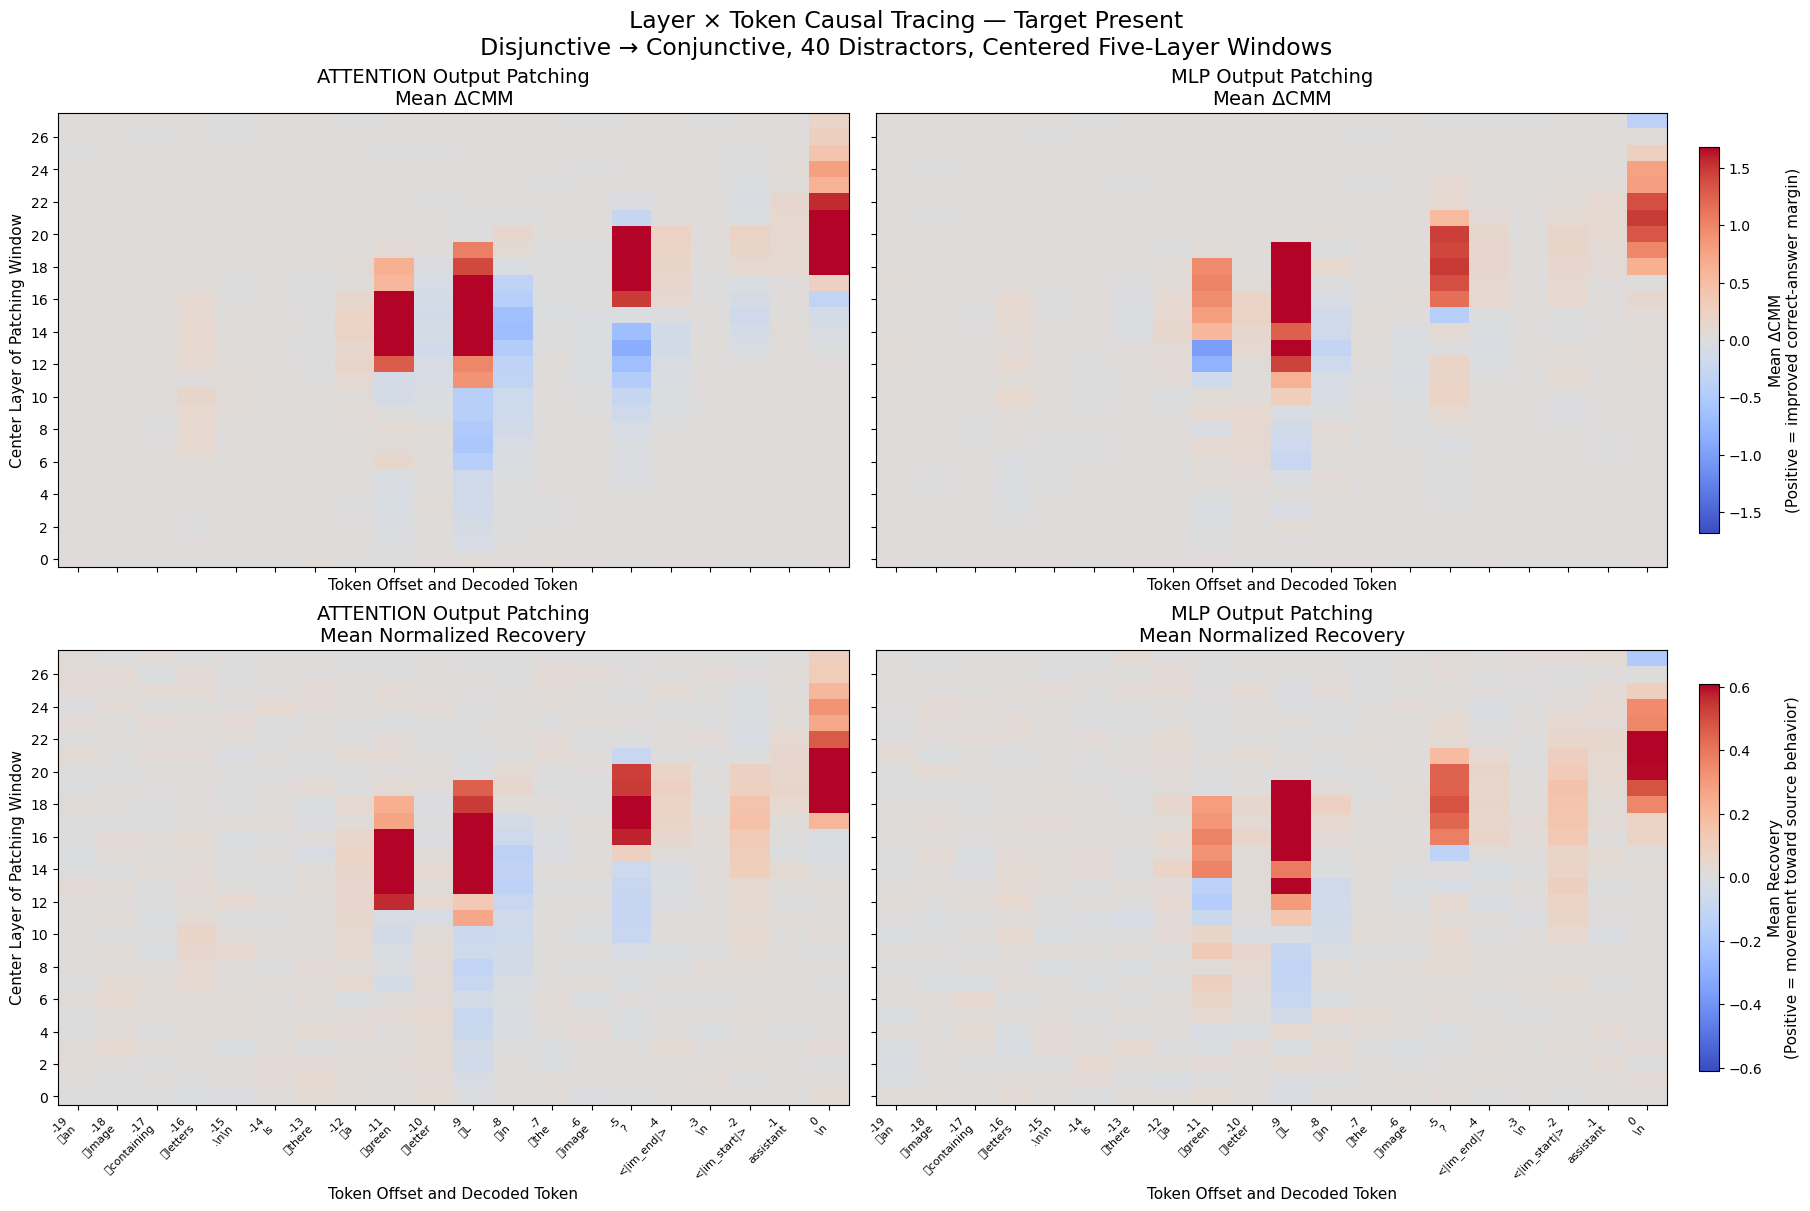

/users/aparasel/.conda/envs/patchscopes-llava/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 9248 (\N{SYMBOL FOR SPACE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


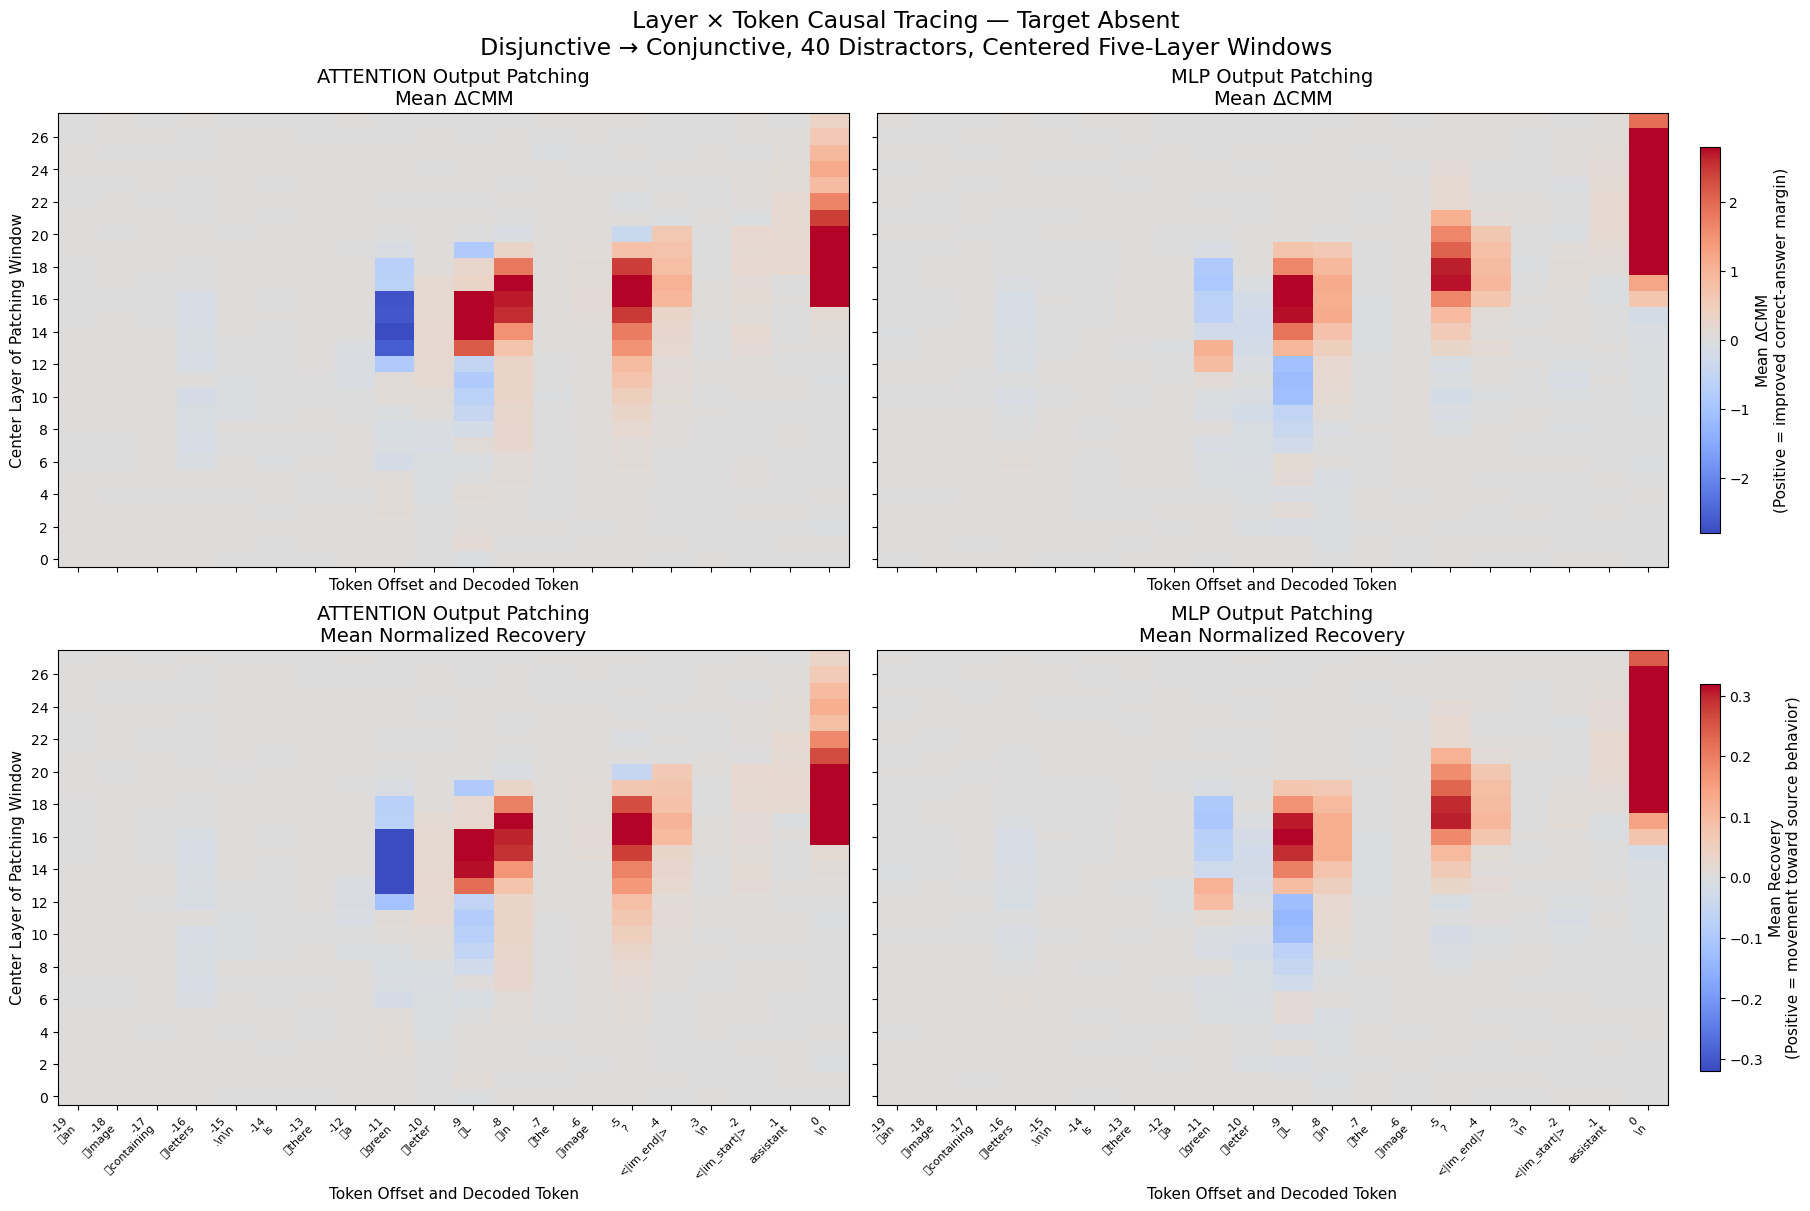

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================================
# PATHS
# ==========================================================

BASE = (
    "/oscar/data/epavlick/aparasel/"
    "Binding-Problem-Brown/Results"
)

RUN_NAME = "disj35_T_to_conj35_layer_token_components_w5"

# Load detailed results, NOT the already-aggregated summary.
FINAL_DETAIL_PATH = f"{BASE}/{RUN_NAME}.csv"
PARTIAL_DETAIL_PATH = f"{BASE}/{RUN_NAME}_partial.csv"

if os.path.exists(FINAL_DETAIL_PATH):
    PATH = FINAL_DETAIL_PATH
elif os.path.exists(PARTIAL_DETAIL_PATH):
    PATH = PARTIAL_DETAIL_PATH
    print("Final detailed results not found; using partial results.")
else:
    raise FileNotFoundError(
        "Could not find either detailed-results file:\n"
        f"{FINAL_DETAIL_PATH}\n"
        f"{PARTIAL_DETAIL_PATH}"
    )

detail_df = pd.read_csv(PATH).copy()

print("Loaded:", PATH)
print("Detailed rows:", len(detail_df))
print("Columns:", detail_df.columns.tolist())

if "target_present" not in detail_df.columns:
    raise ValueError(
        "This file does not contain `target_present`. "
        "Make sure you loaded the detailed CSV rather than *_summary.csv."
    )

# Robust boolean parsing
detail_df["target_present"] = (
    detail_df["target_present"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map({
        "true": True,
        "false": False,
        "1": True,
        "0": False,
    })
)

if detail_df["target_present"].isna().any():
    raise ValueError(
        "Could not parse some `target_present` values:\n"
        f"{detail_df['target_present'].unique()}"
    )

detail_df["recovery"] = detail_df["recovery"].replace(
    [np.inf, -np.inf],
    np.nan,
)


# ==========================================================
# RECREATE SUMMARY, PRESERVING TARGET PRESENCE
# ==========================================================

GROUP_COLUMNS = [
    "component",
    "center_layer",
    "patch_layers",
    "requested_window_size",
    "effective_window_size",
    "token_offset",
    "token_position",
    "token_id",
    "token",
    "target_present",
]

df = (
    detail_df
    .groupby(
        GROUP_COLUMNS,
        as_index=False,
        dropna=False,
    )
    .agg(
        n=("trial", "size"),
        source_accuracy=("source_correct", "mean"),
        target_accuracy=("target_correct", "mean"),
        patched_accuracy=("patched_correct", "mean"),
        mean_source_cmm=("source_cmm", "mean"),
        mean_target_cmm=("target_cmm", "mean"),
        mean_patched_cmm=("patched_cmm", "mean"),
        mean_delta_cmm=("delta_cmm", "mean"),
        median_delta_cmm=("delta_cmm", "median"),
        mean_recovery=("recovery", "mean"),
        median_recovery=("recovery", "median"),
        mean_patch_l2_change=("mean_patch_l2_change", "mean"),
    )
    .sort_values([
        "target_present",
        "component",
        "token_offset",
        "center_layer",
    ])
    .reset_index(drop=True)
)

print("\nExamples per cell:")
print(
    df.groupby("target_present")["n"]
    .agg(["min", "max", "mean"])
    .rename(index={True: "Target present", False: "Target absent"})
)

# Optional: save the correctly split summary for future use.
SPLIT_SUMMARY_PATH = f"{BASE}/{RUN_NAME}_summary_by_target_presence.csv"
df.to_csv(SPLIT_SUMMARY_PATH, index=False)
print("\nSaved split summary:", SPLIT_SUMMARY_PATH)


# ==========================================================
# ORDERING AND TOKEN LABELS
# ==========================================================

components = [
    component
    for component in ["attention", "mlp"]
    if component in df["component"].unique()
]

token_offsets = sorted(df["token_offset"].unique())
center_layers = sorted(df["center_layer"].unique())


def clean_token_label(token):
    token = str(token)

    token = (
        token
        .replace("\n", "\\n")
        .replace("\t", "\\t")
        .replace("\r", "\\r")
        .replace(" ", "␠")
    )

    if len(token) > 14:
        token = token[:11] + "..."

    return token


token_lookup = (
    df[["token_offset", "token"]]
    .drop_duplicates("token_offset")
    .set_index("token_offset")["token"]
    .to_dict()
)

token_labels = [
    f"{offset}\n{clean_token_label(token_lookup.get(offset, '?'))}"
    for offset in token_offsets
]


# ==========================================================
# PLOTTING HELPERS
# ==========================================================

def make_matrix(data, component, metric):
    matrix = (
        data[data["component"] == component]
        .pivot(
            index="center_layer",
            columns="token_offset",
            values=metric,
        )
        .reindex(
            index=center_layers,
            columns=token_offsets,
        )
    )

    return matrix


def safe_symmetric_vmax(values):
    values = values[np.isfinite(values)]

    if len(values) == 0:
        return 1.0

    vmax = np.nanpercentile(np.abs(values), 98)

    return 1.0 if vmax == 0 else vmax


def plot_condition(condition_df, condition_label):
    matrices = {}

    for component in components:
        matrices[(component, "mean_delta_cmm")] = make_matrix(
            condition_df,
            component,
            "mean_delta_cmm",
        )

        matrices[(component, "mean_recovery")] = make_matrix(
            condition_df,
            component,
            "mean_recovery",
        )

    # Color scale is shared across the attention and MLP panels
    # within this target-presence condition.
    delta_values = np.concatenate([
        matrix.to_numpy().ravel()
        for (component, metric), matrix in matrices.items()
        if metric == "mean_delta_cmm"
    ])

    recovery_values = np.concatenate([
        matrix.to_numpy().ravel()
        for (component, metric), matrix in matrices.items()
        if metric == "mean_recovery"
    ])

    delta_vmax = safe_symmetric_vmax(delta_values)
    recovery_vmax = safe_symmetric_vmax(recovery_values)

    fig, axes = plt.subplots(
        2,
        len(components),
        figsize=(18, 12),
        sharex=True,
        sharey=True,
        constrained_layout=True,
    )

    axes = np.asarray(axes)
    if len(components) == 1:
        axes = axes.reshape(2, 1)

    delta_images = []
    recovery_images = []

    for column_index, component in enumerate(components):

        # --------------------------------------------------
        # Mean delta CMM
        # --------------------------------------------------

        delta_matrix = matrices[(component, "mean_delta_cmm")]
        ax = axes[0, column_index]

        image = ax.imshow(
            delta_matrix.values,
            aspect="auto",
            origin="lower",
            interpolation="nearest",
            cmap="coolwarm",
            vmin=-delta_vmax,
            vmax=delta_vmax,
        )

        delta_images.append(image)

        ax.set_title(
            f"{component.upper()} Output Patching\n"
            r"Mean $\Delta$CMM",
            fontsize=14,
        )

        # --------------------------------------------------
        # Mean normalized recovery
        # --------------------------------------------------

        recovery_matrix = matrices[(component, "mean_recovery")]
        ax = axes[1, column_index]

        image = ax.imshow(
            recovery_matrix.values,
            aspect="auto",
            origin="lower",
            interpolation="nearest",
            cmap="coolwarm",
            vmin=-recovery_vmax,
            vmax=recovery_vmax,
        )

        recovery_images.append(image)

        ax.set_title(
            f"{component.upper()} Output Patching\n"
            "Mean Normalized Recovery",
            fontsize=14,
        )

    # ------------------------------------------------------
    # Axis labels
    # ------------------------------------------------------

    y_step = 2

    for row_index in range(2):
        for column_index in range(len(components)):
            ax = axes[row_index, column_index]

            ax.set_yticks(
                np.arange(0, len(center_layers), y_step)
            )
            ax.set_yticklabels(center_layers[::y_step])

            ax.set_xticks(np.arange(len(token_offsets)))
            ax.set_xticklabels(
                token_labels,
                rotation=45,
                ha="right",
                fontsize=8,
            )

            ax.set_xlabel(
                "Token Offset and Decoded Token",
                fontsize=11,
            )

            if column_index == 0:
                ax.set_ylabel(
                    "Center Layer of Patching Window",
                    fontsize=11,
                )

    # ------------------------------------------------------
    # Colorbars
    # ------------------------------------------------------

    delta_colorbar = fig.colorbar(
        delta_images[0],
        ax=axes[0, :].tolist(),
        shrink=0.85,
        pad=0.02,
    )

    delta_colorbar.set_label(
        r"Mean $\Delta$CMM"
        "\n(Positive = improved correct-answer margin)",
        fontsize=11,
    )

    recovery_colorbar = fig.colorbar(
        recovery_images[0],
        ax=axes[1, :].tolist(),
        shrink=0.85,
        pad=0.02,
    )

    recovery_colorbar.set_label(
        "Mean Recovery"
        "\n(Positive = movement toward source behavior)",
        fontsize=11,
    )

    fig.suptitle(
        f"Layer × Token Causal Tracing — Target {condition_label}\n"
        "Disjunctive → Conjunctive, 40 Distractors, "
        "Centered Five-Layer Windows",
        fontsize=17,
    )

    plt.show()


# ==========================================================
# TARGET-PRESENT FIGURE
# ==========================================================

plot_condition(
    df[df["target_present"]].copy(),
    condition_label="Present",
)


# ==========================================================
# TARGET-ABSENT FIGURE
# ==========================================================

plot_condition(
    df[~df["target_present"]].copy(),
    condition_label="Absent",
)